# Bayesian Inference for Binary Star Eccentricities

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 2 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://statml.org/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

Binary stars are pairs of stars that are bound by gravity and orbit their common center of mass. They are among the most important objects in astrophysics. Binaries give direct measurements of stellar masses, test theories of stellar evolution and probe the physics of star formation. Yet measuring the orbital properties of a binary is still a hard observational task.

The usual approach needs long monitoring campaigns. Astronomers observe a binary over multiple orbital periods and track the positions and velocities of both stars along their elliptical paths. For orbital periods of years or decades, this takes a large share of telescope time, which is not possible for large populations.

This tutorial studies another approach, inspired by [Hwang et al. (2022)](https://ui.adsabs.harvard.edu/abs/2022MNRAS.512.3383H/abstract). We use Bayesian inference to constrain the orbital eccentricity from a single epoch of observation. One observation already carries information about the orbit. At one moment we measure the relative position and velocity of the two stars. The angle $\gamma$ between these two vectors gives a statistical constraint on the eccentricity $e$.

We build the Bayesian analysis step by step and learn how the following ideas work.

- The angle $\gamma$ relates to the eccentricity for a Keplerian orbit.
- A likelihood connects an observable quantity to a physical parameter.
- Marginalization over the unknown orbital phase gives a probabilistic constraint on the eccentricity.
- A measurement error changes the inference.

This example shows how Bayesian methods turn limited data into physical constraints, even when a deterministic approach fails.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Working knowledge of Python, NumPy, matplotlib
- Probability distributions, Bayes' theorem and the likelihood
- Marginalization and posterior distributions
- Introductory knowledge of stellar properties and orbital mechanics

### Learning Objectives

After this tutorial you can do the following.

- Construct a likelihood and a posterior for an astronomical observation
- Build a forward model that connects physical parameters to an observable quantity
- Propagate a measurement error with marginalization
- Compute Bayesian results on a grid for a low-dimensional parameter space
- Connect the mathematics to the orbital mechanics

We begin by importing the libraries and setting the plot style.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import LogNorm

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 10]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Color maps of the book, white to a palette color to its dark shade, and blue-white-red
book_maps = [('book_blue', 'w', 'C0', '#172F4C'), ('book_green', 'w', 'C2', '#153F32'),
             ('book_orange', 'w', 'C1', '#724D1D'), ('book_div', 'C0', 'w', 'C3'),
             ('book_grey', 'w', '#9E9E9E', '#222222')]
for name, *colors in book_maps:
    plt.colormaps.register(LinearSegmentedColormap.from_list(name, colors), force=True)

# Color palette

# Random seed for reproducibility
np.random.seed(42)

%matplotlib inline

## Understanding Binary Star Orbits

Binary stars orbit their common center of mass and follow Kepler's laws, as planets orbit the Sun. The shape and orientation of an orbit carry information about the formation history and the dynamical evolution of the system. To build the Bayesian analysis, we first need to know how orbital parameters give quantities that we can observe.

### Orbital Parameters

Several parameters describe a binary orbit completely, and we use two of them. The orbit is the relative orbit, the path of the secondary star around the primary star. It is an ellipse with the primary at one focus.

1. The semi-major axis $a$ is the size scale of the orbit. It sets the average separation between the stars.
2. The eccentricity $e$ measures how stretched the orbit is. It runs from 0 (circular) to nearly 1 (highly elongated).

We view the orbit face-on, with the line of sight along the normal of the orbital plane.

The eccentricity is important for understanding how binaries form. Different formation mechanisms predict different eccentricity distributions.

- Capture often produces highly eccentric orbits.
- Disk fragmentation tends to produce nearly circular orbits.
- Dynamical interactions can produce a thermal distribution of eccentricities, with $p(e) \propto e$, which favors high eccentricities.

When we measure the eccentricity distribution of a population of binaries, we can find which mechanisms dominate in different regions. The eccentricity is therefore a useful probe of binary star physics.

We now plot face-on orbits for several eccentricities. The plots mark the periapsis, the point closest to the primary, and the apoapsis, the farthest point.

### Effect of Eccentricity on Orbit Shape

The eccentricity controls the shape of the orbit. A circular orbit ($e = 0$) keeps a constant separation between the stars. A highly eccentric orbit ($e \to 1$) brings the stars much closer at the periapsis than at the apoapsis. This change in separation affects the velocities and accelerations that we observe along the orbit. We plot orbits with $e = 0$, 0.5 and 0.8.

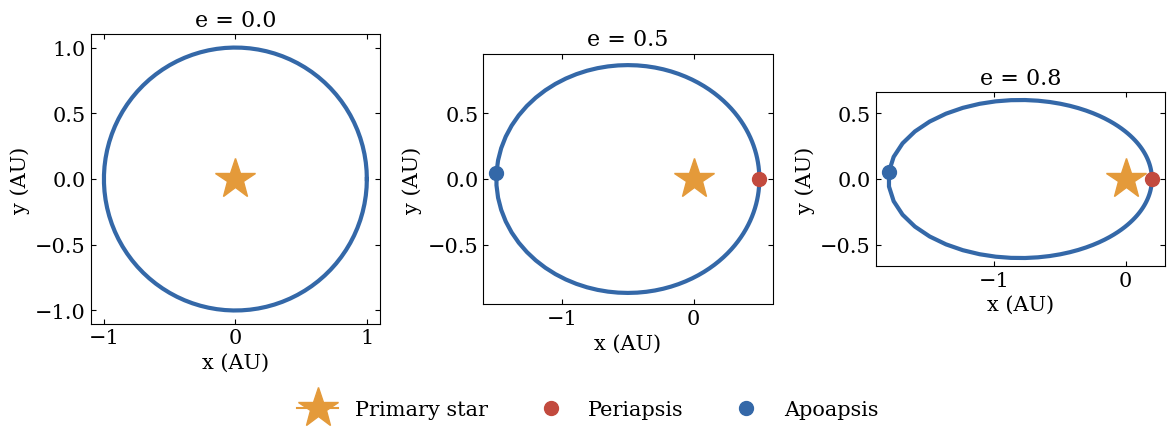

In [2]:
# Demonstrate the effect of eccentricity on orbit shape
eccentricities = [0.0, 0.5, 0.8]
fig, axes = plt.subplots(1, len(eccentricities), figsize=(12, 4.8))

# True anomaly (angle from the periapsis)
theta = np.linspace(0, 2*np.pi, 100)

for ax, e in zip(axes, eccentricities):
    # Radius from the polar equation of the ellipse, then Cartesian coordinates
    r = (1 - e**2) / (1 + e * np.cos(theta))
    x = r * np.cos(theta)
    y = r * np.sin(theta)

    # The orbit and the primary star at one focus
    ax.plot(x, y, color='C0', linewidth=3)
    ax.plot([0], [0], color='C1', marker='*', markersize=30, label='Primary star')

    # Mark the periapsis (closest approach) and the apoapsis (farthest point), which a circular orbit does not have
    if e > 0:
        ax.plot(x[np.argmin(r)], y[np.argmin(r)], 'o', color='C3', markersize=10, label='Periapsis')
        ax.plot(x[np.argmax(r)], y[np.argmax(r)], 'o', color='C0', markersize=10, label='Apoapsis')

    # Labels and title
    ax.set_aspect('equal')
    ax.set_xlabel('x (AU)')
    ax.set_ylabel('y (AU)')
    ax.set_title(f'e = {e}')

# One legend below the panels
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


## The Physics of Orbital Motion

To infer the eccentricity, we need to know how the stars move along the orbit. At any point of a binary orbit, the relative position vector $\mathbf{r}$ and the relative velocity vector $\mathbf{v}$ form an angle. This angle depends on the eccentricity and on the orbital phase $\phi$, the angle of $\mathbf{r}$ measured from the periapsis. The relation lets us infer the eccentricity from a single epoch.

### The Velocity-Position Angle

Consider a point on the elliptical orbit. The position vector points from the primary to the secondary. The velocity vector is the velocity of the secondary relative to the primary, and it points along the direction of motion. The angle $\gamma$ between the two vectors changes around the orbit.

For a Keplerian orbit viewed face-on, the position and the velocity at the orbital phase $\phi$ are

$$\mathbf{r} = r\,(\cos\phi, \sin\phi), \quad r = \frac{1 - e^2}{1 + e\cos\phi}, \qquad \mathbf{v} = \frac{(-\sin\phi, \; e + \cos\phi)}{\sqrt{1 - e^2}}.$$

The velocity is the time derivative of the position along the orbit. The scale of the velocity does not matter for the angle, so we use units with $a = 1$ and $G(M_1 + M_2) = 1$.

The change of $\gamma$ shows the shape of the orbit, so even one observation of $\gamma$ gives a statistical constraint on the eccentricity. We now compute these vectors and the angle between them. We plot them for a circular orbit and for an orbit with $e = 0.7$.

For a circular orbit ($e = 0$), the velocity is always perpendicular to the position vector, so the angle stays at 90° throughout the orbit. For an eccentric orbit, $\gamma$ is 90° at the periapsis and the apoapsis. It falls below 90° on one half of the orbit and rises above it on the other half. As the eccentricity increases, the angle varies more, so the geometry at one instant carries information about the shape of the orbit.

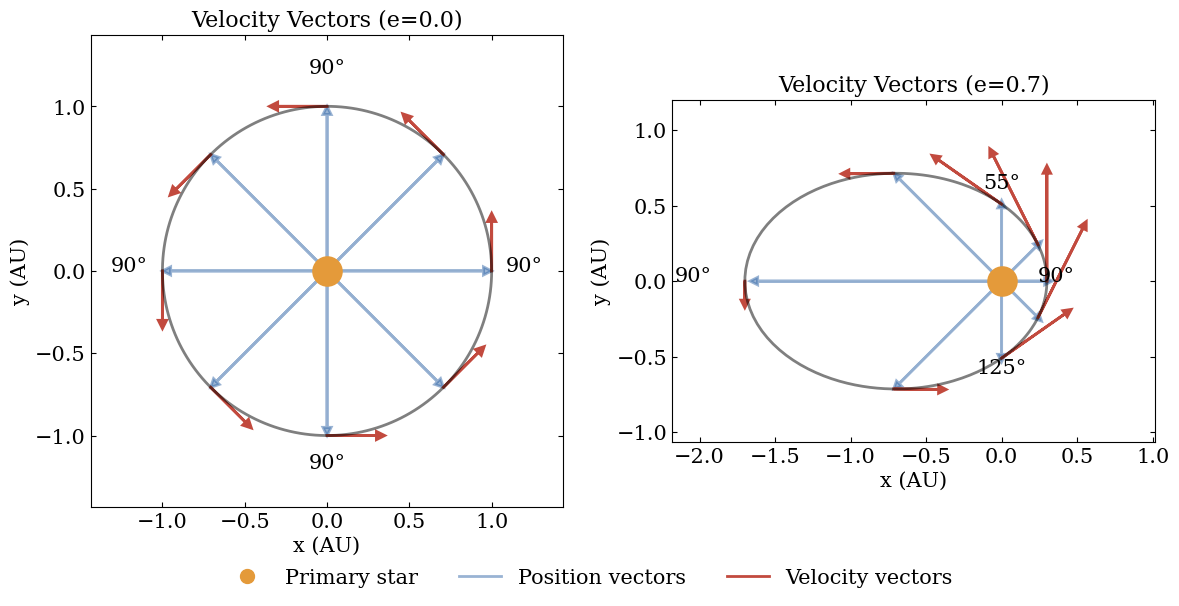

In [3]:
# Demonstrate for different eccentricities
eccentricities = [0.0, 0.7]
fig, axes = plt.subplots(1, len(eccentricities), figsize=(12, 6))

# Full orbit and the selected points for the vectors
theta_full = np.linspace(0, 2*np.pi, 200)
theta_points = np.array([0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi,
                        5*np.pi/4, 3*np.pi/2, 7*np.pi/4])

for ax, e in zip(axes, eccentricities):
    # Position along the full orbit, from the polar equation of the ellipse
    r_full = (1 - e**2) / (1 + e * np.cos(theta_full))
    x_full = r_full * np.cos(theta_full)
    y_full = r_full * np.sin(theta_full)

    # Position and velocity at the selected points, in units with a = 1 and G(M1 + M2) = 1
    r = (1 - e**2) / (1 + e * np.cos(theta_points))
    x = r * np.cos(theta_points)
    y = r * np.sin(theta_points)

    # The velocity is the time derivative of the position
    vx = -np.sin(theta_points) / np.sqrt(1 - e**2)
    vy = (np.cos(theta_points) + e) / np.sqrt(1 - e**2)

    # Orbit and primary star
    ax.plot(x_full, y_full, '-', color='k', linewidth=2, alpha=0.5)
    ax.plot(0, 0, 'o', color='C1', markersize=20, markeredgecolor='C1', markeredgewidth=2)

    # Scale the velocity vectors for visibility
    scale = 0.3

    for i in range(len(x)):
        # Position vector (from the primary to the star)
        ax.arrow(0, 0, x[i]*0.95, y[i]*0.95,
                 head_width=0.05, head_length=0.05,
                 fc='C0', ec='C0', alpha=0.5, linewidth=2)

        # Velocity vector (from the star position)
        ax.arrow(x[i], y[i], vx[i]*scale, vy[i]*scale,
                 head_width=0.05, head_length=0.05,
                 fc='C3', ec='C3', linewidth=2)

        # Angle between the two vectors, from the dot product
        dot_product = (x[i]*vx[i] + y[i]*vy[i]) / (np.sqrt(x[i]**2 + y[i]**2) *
                                                    np.sqrt(vx[i]**2 + vy[i]**2))
        angle = np.degrees(np.arccos(np.clip(dot_product, -1, 1)))  # clip keeps arccos in range

        # Add the angle annotation at every other point to avoid crowding
        if i % 2 == 0:
            ax.annotate(f'{angle:.0f}°', xy=(x[i]*1.2, y[i]*1.2), fontsize=15, ha='center')

    # Labels and title, with room around the orbit for the angle labels
    ax.set_aspect('equal')
    ax.margins(0.2)
    ax.set_xlabel('x (AU)')
    ax.set_ylabel('y (AU)')
    ax.set_title(f'Velocity Vectors (e={e})')

# Empty lines give the legend entries, shown once below the panels
axes[-1].plot([], [], 'o', color='C1', markersize=10, markeredgecolor='C1', label='Primary star')
axes[-1].plot([], [], color='C0', alpha=0.5, linewidth=2, label='Position vectors')
axes[-1].plot([], [], color='C3', linewidth=2, label='Velocity vectors')
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3)

plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


## Mathematical Formulation: From Angles to Eccentricity

The figure shows how $\gamma$ changes around the orbit. The Bayesian analysis needs $\gamma$ as a function of the orbital parameters. The dot product of the two vectors above gives it in closed form. Their dot product is $\mathbf{r}\cdot\mathbf{v} = r e\sin\phi/\sqrt{1 - e^2}$, and their lengths are $|\mathbf{r}| = r$ and $|\mathbf{v}| = \sqrt{1 + e^2 + 2e\cos\phi}/\sqrt{1 - e^2}$. The factors of $r$ and $\sqrt{1 - e^2}$ cancel, so

$$\cos\gamma = \frac{\mathbf{r}\cdot\mathbf{v}}{|\mathbf{r}||\mathbf{v}|} = \frac{e\sin\phi}{\sqrt{1 + e^2 + 2e\cos\phi}},$$

where

- $e$ is the eccentricity, with $0 \le e < 1$,
- $\phi$ is the orbital phase, with $0 \le \phi < 2\pi$.

This equation gives the full relation between the shape of the orbit and the geometry at one instant. It explains what the figure shows. A circular orbit ($e = 0$) has a numerator of zero, so $\gamma = 90°$ everywhere. At the periapsis ($\phi = 0$) and the apoapsis ($\phi = \pi$) the sine term vanishes, so $\gamma = 90°$.

We now implement this relation and explore it.


In [4]:
def cos_gamma(e, phi):
    """
    Cosine of the angle between the position and the velocity vector of a face-on orbit.

    The inputs are the eccentricity e and the orbital phase phi in radians.
    """
    numerator = e * np.sin(phi)
    denominator = np.sqrt(1.0 + e**2 + 2.0*e*np.cos(phi))

    # Avoid a division by zero with a small floor
    cos_gamma = numerator / np.maximum(denominator, 1e-15)

    # Keep the value in the range of a cosine
    return np.clip(cos_gamma, -1.0, 1.0)

We now plot $\gamma$ against the orbital phase for five eccentricities.


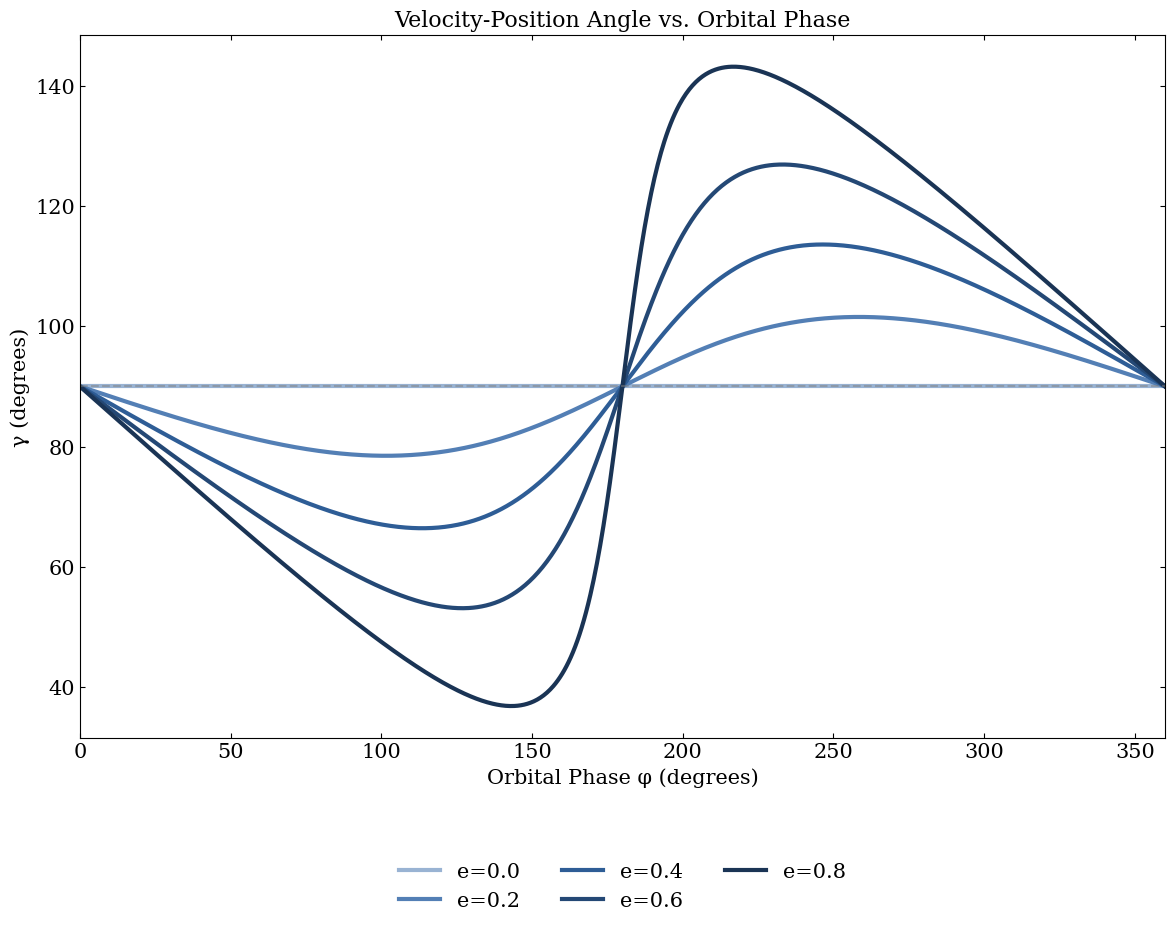

In [5]:
# Explore how the angle varies with orbital phase for different eccentricities
fig, ax = plt.subplots(figsize=(12.0, 9.6))

phi_range = np.linspace(0, 2*np.pi, 1000)
eccentricities = [0.0, 0.2, 0.4, 0.6, 0.8]
colors = plt.colormaps['book_blue'](np.linspace(0.25, 0.95, len(eccentricities)))

for e, color in zip(eccentricities, colors):
    # Angle in degrees from its cosine
    gamma = np.degrees(np.arccos(cos_gamma(e, phi_range)))
    ax.plot(phi_range*180/np.pi, gamma, color=color, linewidth=3, label=f'e={e}')

ax.set_xlabel('Orbital Phase φ (degrees)')
ax.set_ylabel('γ (degrees)')
ax.set_title('Velocity-Position Angle vs. Orbital Phase')

# Legend, limits and the 90 degree line
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
ax.set_xlim(0, 360)
ax.axhline(y=90, color='gray', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

The angle varies periodically with the orbital phase, and the eccentricity sets the size of the variation. As the eccentricity increases, we see symmetric oscillations around 90° with a growing amplitude. The extrema occur at intermediate orbital phases and not at the periapsis or the apoapsis. Their location depends on the eccentricity.

For any observed angle $\gamma \ne 90°$, many combinations of $e$ and $\phi$ give the same angle. This degeneracy is part of every single-epoch observation. The curves are also symmetric. Replacing $\phi$ by $2\pi - \phi$ turns $\gamma$ into $180° - \gamma$, which follows from the symmetry of the orbit.


## Bayesian Inference: From Observations to Eccentricity

We now have the relation between the angle $\gamma$ and the eccentricity $e$. Next we build a Bayesian method that infers $e$ from observations.

### The Forward Problem

We have already solved the forward problem. Given $e$ and $\phi$, the closed form above gives the angle that we expect. In practice, however, we measure $\gamma$ and want to infer $e$. This is an inverse problem. Bayesian inference handles the uncertainties that come with it.

### Constructing the Likelihood Function

The first step is to build the likelihood $p(\gamma|e)$. It gives the probability of observing the angle $\gamma$ when the true eccentricity is $e$. The orbital phase $\phi$ is unknown and random for a single observation, so we marginalize over it (Section 2.5),

$$p(\gamma|e) = \int_0^{2\pi} p(\gamma|e,\phi) p(\phi) \mathrm{d}\phi.$$

We assume a uniform distribution of the phase, $p(\phi) = 1/(2\pi)$. The integral is then an average over all orbital phases. We evaluate it numerically by drawing random phases. For one eccentricity, the histogram of the angles that these phases give shows $p(\gamma|e)$ as a function of the angle $\gamma$.


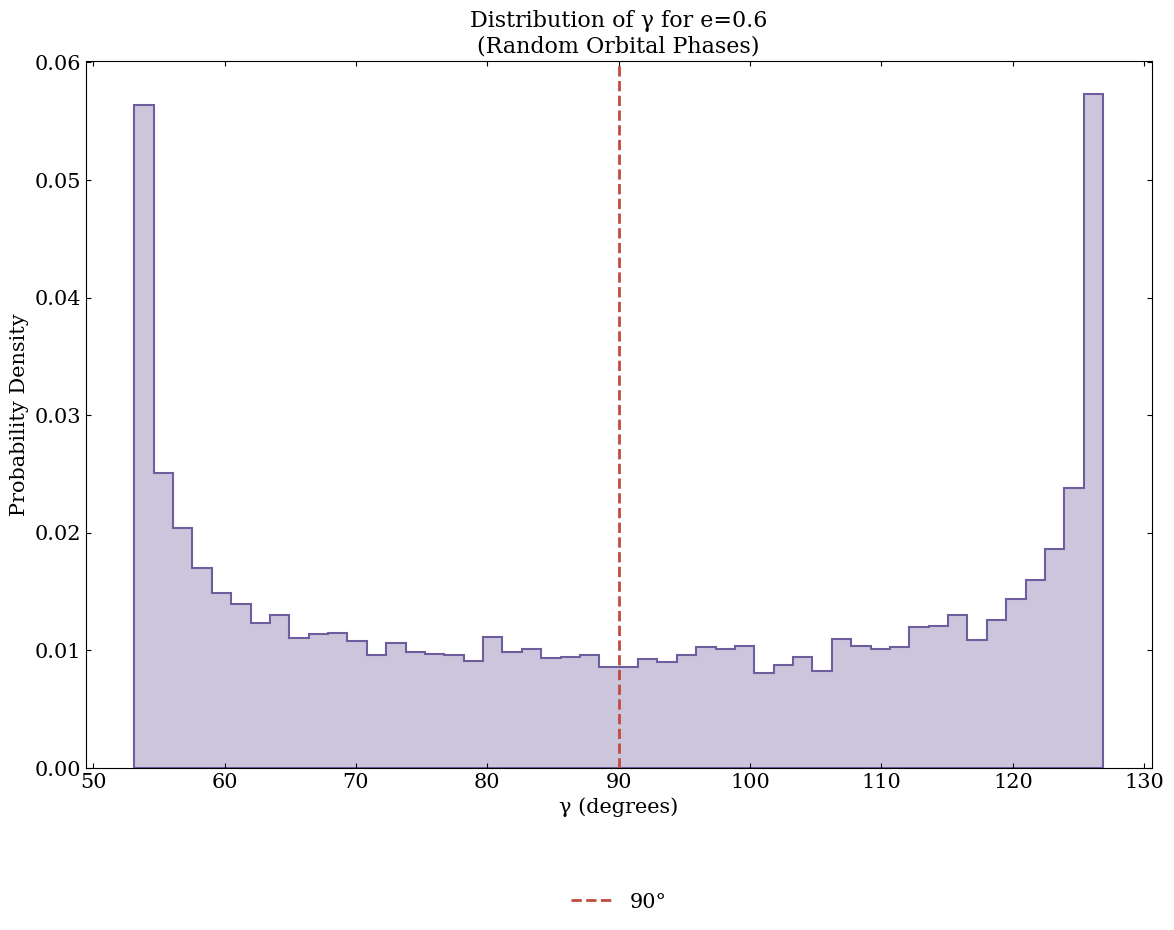

In [6]:
# Distribution of angles for a fixed eccentricity with random orbital phases
fig, ax = plt.subplots(figsize=(12.0, 9.6))

e_test = 0.6
n_samples = 10000
phi_random = np.random.uniform(0, 2*np.pi, n_samples)  # uniform random phases
gamma_random = np.degrees(np.arccos(cos_gamma(e_test, phi_random)))  # angle in degrees

# Histogram of the angles, with the 90 degree line
ax.hist(gamma_random, bins=50, density=True,
        histtype='stepfilled', facecolor=('C4', 0.35), edgecolor='C4', linewidth=1.5)
ax.axvline(x=90, color='C3', linestyle='--', linewidth=2, label='90°')

# Labels and title
ax.set_xlabel('γ (degrees)')
ax.set_ylabel('Probability Density')
ax.set_title(f'Distribution of γ for e={e_test}\n(Random Orbital Phases)')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

plt.tight_layout()
plt.show()

The histogram is bimodal, with its peaks away from 90°. The likelihood of an observed angle is the height of the histogram at that angle. We now repeat this for every eccentricity on a grid. For each $e$ we draw random phases and count the fraction of angles in a bin of 1° around the observed angle.


In [7]:
def compute_likelihood_grid(gamma_obs_deg, e_values, n_phase_samples=10000):
    """
    Likelihood p(γ|e) on a grid of eccentricities, in units of 1/degree.

    We average over random orbital phases.
    """
    likelihood = np.zeros_like(e_values)

    # Width of the γ bin in degrees, the resolution of the observation
    bin_width = 1.0

    for i, e in enumerate(e_values):
        # Sample random orbital phases
        phi_samples = np.random.uniform(0, 2*np.pi, n_phase_samples)

        # Calculate γ for each phase
        gamma_samples = np.degrees(np.arccos(cos_gamma(e, phi_samples)))

        # Count the fraction of phases in the bin around the observed angle
        within_bin = np.abs(gamma_samples - gamma_obs_deg) < bin_width/2
        likelihood[i] = np.mean(within_bin) / bin_width  # fraction per degree

    return likelihood

To see the likelihood for every eccentricity at once, we compute a map of $p(\gamma|e)$ over the observed angle and the eccentricity.


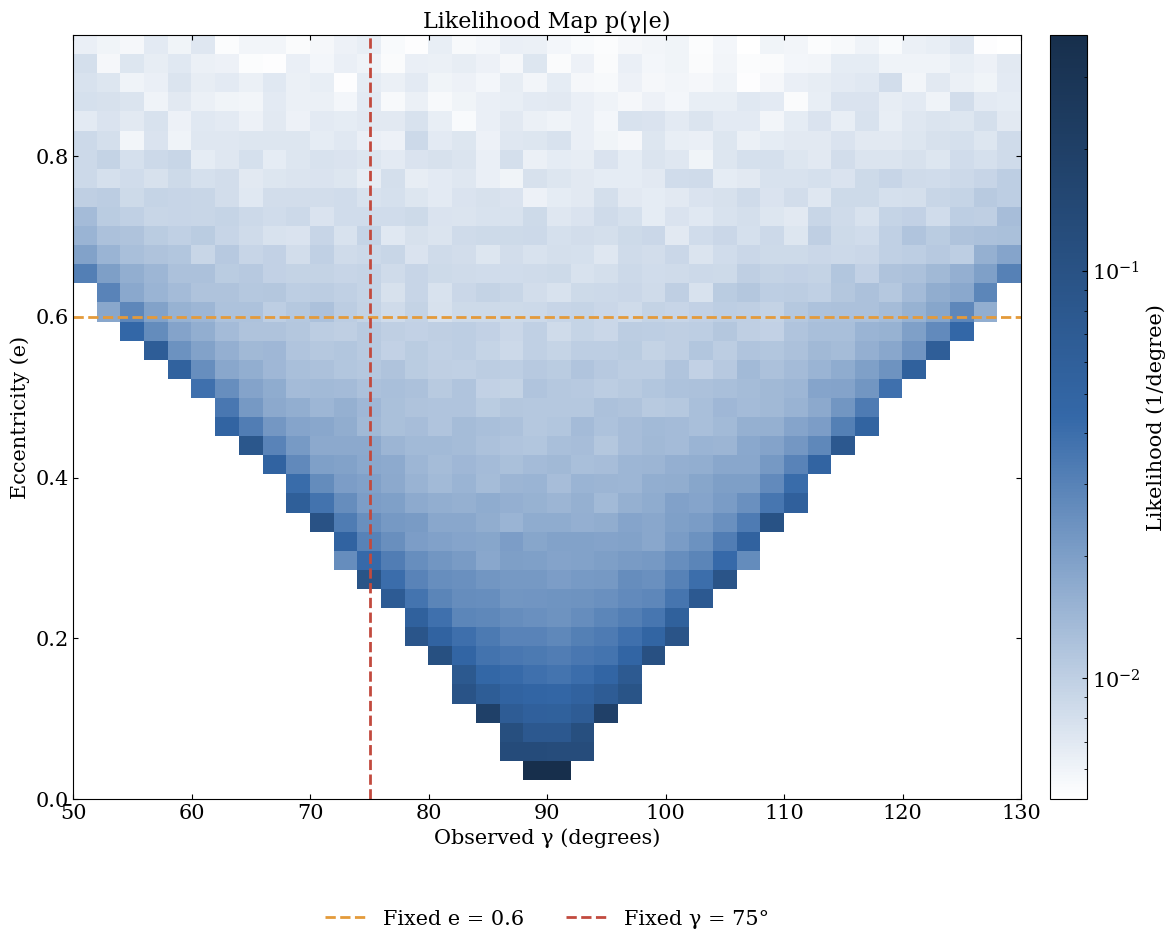

In [8]:
# Create a 2D likelihood map
fig, ax = plt.subplots(figsize=(12.0, 9.7))

gamma_range = np.linspace(50, 130, 40)
e_range = np.linspace(0, 0.95, 40)
likelihood_map = np.zeros((len(gamma_range), len(e_range)))

for i, gamma in enumerate(gamma_range):
    likelihood_map[i, :] = compute_likelihood_grid(gamma, e_range, n_phase_samples=20000)

# Zero likelihood gets no color on the log scale
likelihood_map[likelihood_map == 0] = np.nan

# Color map of the likelihood on a log scale
im = ax.imshow(likelihood_map.T, origin='lower', aspect='auto',
               extent=[gamma_range[0], gamma_range[-1], e_range[0], e_range[-1]],
               cmap='book_blue', norm=LogNorm())

# A slice at one eccentricity and a slice at one observed angle
ax.axhline(0.6, color='C1', linestyle='--', linewidth=2, label='Fixed e = 0.6')
ax.axvline(75, color='C3', linestyle='--', linewidth=2, label='Fixed γ = 75°')

# Labels, title, legend below the panel and a color bar with the height of the panel
ax.set_xlabel('Observed γ (degrees)')
ax.set_ylabel('Eccentricity (e)')
ax.set_title('Likelihood Map p(γ|e)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
cax = ax.inset_axes([1.03, 0, 0.04, 1])
fig.colorbar(im, cax=cax, label='Likelihood (1/degree)')

plt.tight_layout()
plt.show()


The likelihood is nonzero in a V-shaped region. For each eccentricity the angles lie between $\arccos e$ and $180° - \arccos e$, so the region widens as $e$ grows. At $e = 0$ every angle is 90°. The likelihood is highest along the edges of the V, where the histogram peaks.

The two slices show how we use the map. A horizontal slice at one eccentricity is the histogram above, the probability of each angle for that $e$. A vertical slice at the observed angle is the likelihood as a function of $e$. It says how well each eccentricity explains that angle, and it is zero below the lower edge of the V, at $e = |\cos\gamma|$.


### From Likelihood to Posterior: Applying Bayes' Theorem

With the likelihood in hand, we apply Bayes' theorem to infer the posterior distribution of the eccentricity given the observed angle,

$$p(e|\gamma) = \frac{p(\gamma|e) p(e)}{p(\gamma)},$$

where

- $p(e|\gamma)$ is the **posterior**, the probability of the eccentricity given our observation,
- $p(\gamma|e)$ is the **likelihood**, which we just defined,
- $p(e)$ is the **prior**, our belief about the eccentricity before the observation,
- $p(\gamma)$ is the **evidence**, a normalization constant.

We use an uninformative uniform prior, $p(e) = 1$ for $e \in [0,1]$. It says that all eccentricities are equally likely before we see the data. The evidence $p(\gamma)$ only makes the posterior integrate to 1. We can therefore ignore it and normalize at the end. With a uniform prior, the posterior is the vertical slice of the likelihood map at the observed angle, normalized to integrate to 1.

In [9]:
def trapezoid(y, x):
    """Integrate y over x with the trapezoid rule."""
    return np.sum((y[1:] + y[:-1]) * np.diff(x)) / 2

def calculate_posterior(gamma_obs_deg, e_grid=None, n_samples=50000):
    """
    Posterior p(e|γ) on a grid of eccentricities for a uniform prior p(e) = 1.

    The posterior is proportional to the likelihood.
    """
    if e_grid is None:
        e_grid = np.linspace(0, 0.99, 100)

    # Calculate the likelihood
    likelihood = compute_likelihood_grid(gamma_obs_deg, e_grid, n_samples)

    # With a uniform prior, the posterior is proportional to the likelihood
    posterior = likelihood.copy()

    # Normalize to integrate to 1 (trapezoid rule over e)
    posterior = posterior / trapezoid(posterior, e_grid)

    return e_grid, posterior

We apply the method to four observed angles. For each angle we plot the posterior and mark the maximum a posteriori (MAP) value, which is the eccentricity at the maximum. We also shade the shortest interval that holds 68% of the probability. It always contains the MAP.

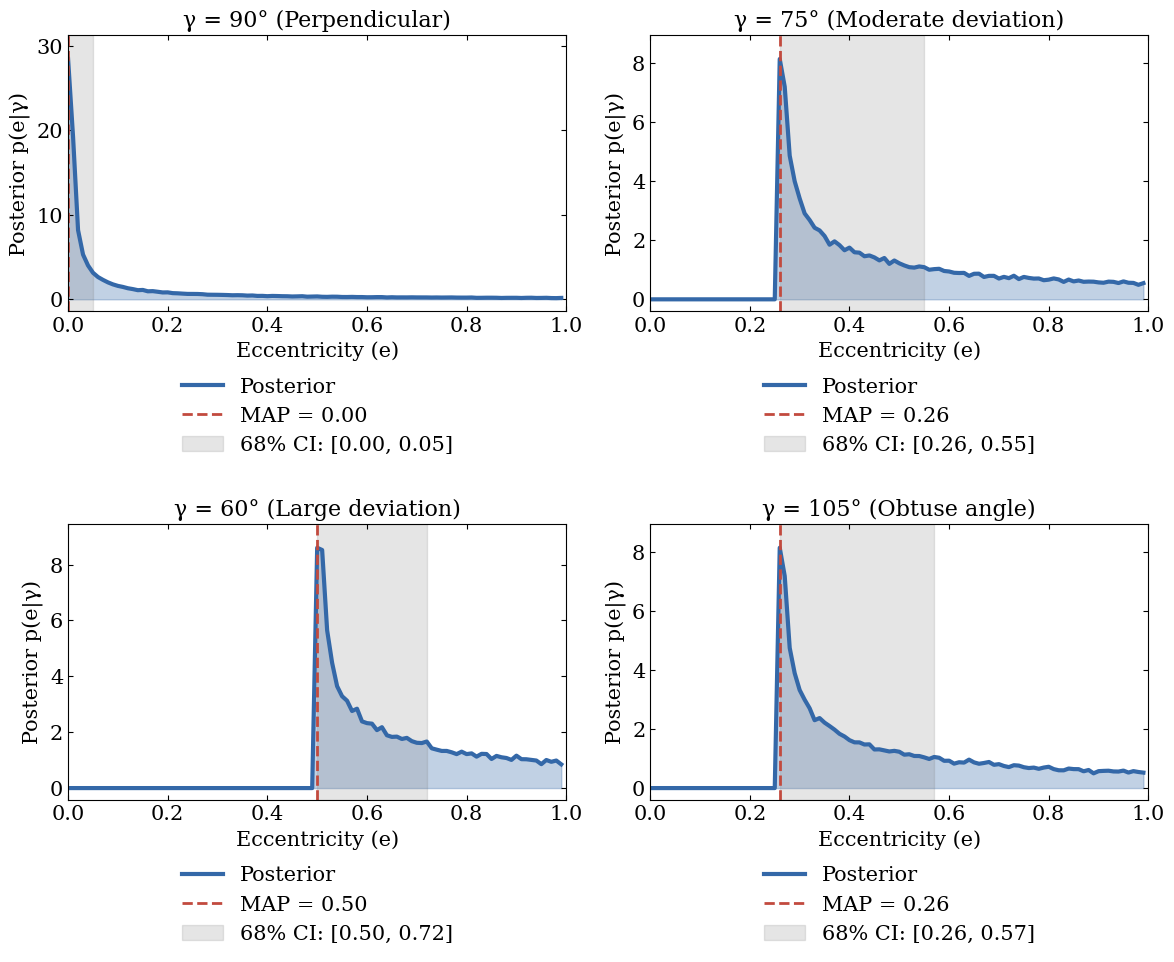

In [10]:
# Demonstrate Bayesian inference for different observations
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Test cases, with the observed angle, the title and the panel
test_cases = [
    (90, "γ = 90° (Perpendicular)", axes[0,0]),
    (75, "γ = 75° (Moderate deviation)", axes[0,1]),
    (60, "γ = 60° (Large deviation)", axes[1,0]),
    (105, "γ = 105° (Obtuse angle)", axes[1,1])
]

for gamma_obs, title, ax in test_cases:
    # Calculate the posterior
    e_grid, posterior = calculate_posterior(gamma_obs)

    # Find the maximum a posteriori (MAP) estimate
    map_idx = np.argmax(posterior)
    map_estimate = e_grid[map_idx]

    # Calculate the shortest interval that holds 68% of the probability
    # Add the grid points from the highest posterior value downwards until they hold 68%
    order = np.argsort(posterior)[::-1]
    mass = np.cumsum(posterior[order]) * (e_grid[1] - e_grid[0])

    # The grid points inside the interval
    inside = order[:np.searchsorted(mass, 0.68) + 1]
    lower_idx, upper_idx = inside.min(), inside.max()

    # Plot the posterior
    ax.fill_between(e_grid, 0, posterior, alpha=0.3, color='C0')
    ax.plot(e_grid, posterior, '-', color='C0', linewidth=3, label='Posterior')
    ax.axvline(map_estimate, color='C3', linestyle='--', linewidth=2,
               label=f'MAP = {map_estimate:.2f}')

    # Shade the 68% interval
    ax.axvspan(e_grid[lower_idx], e_grid[upper_idx], alpha=0.2, color='gray',
               label=f'68% CI: [{e_grid[lower_idx]:.2f}, {e_grid[upper_idx]:.2f}]')

    # Labels, title and limits
    ax.set_xlabel('Eccentricity (e)')
    ax.set_ylabel('Posterior p(e|γ)')
    ax.set_title(title)

    # Legend below the panel and limits
    ax.legend(ncol=1, loc='upper center', bbox_to_anchor=(0.5, -0.17))
    ax.set_xlim(0, 1)
    ax.set_ylim(top=1.1 * posterior.max())

plt.tight_layout()
plt.show()

The posterior for $\gamma = 90°$ peaks at $e = 0$, because a circular orbit always has $\gamma = 90°$. For $75°$ and $60°$ the posterior starts at a minimum eccentricity, because large deviations from 90° need elongated orbits. This minimum grows as the angle moves away from 90°. The posterior also keeps a long tail toward $e = 1$. One angle therefore sets a lower limit on the eccentricity but does not fix it. The angle $105°$ gives the same posterior as $75°$, by symmetry.

Bayesian inference does not always need a complex method. Our inverse problem infers one parameter from one observation, so a grid works well. We evaluate the likelihood on a grid of eccentricities and apply Bayes' theorem directly. This gives the full posterior distribution and the complete uncertainty, and it needs little computing time.

A grid becomes too expensive when the number of parameters grows, because the number of grid points grows quickly. For one or two parameters, a grid remains a good method.

## Including Measurement Uncertainties

In real observations, we do not measure $\gamma$ perfectly. The measured angle $\gamma_{\mathrm{meas}}$ comes with an uncertainty, which we describe with a standard deviation $\sigma_\gamma$. We must include this uncertainty in the Bayesian analysis.

### Marginalizing Over Measurement Uncertainty

We take a Gaussian measurement error,

$$p(\gamma_{\mathrm{meas}}|\gamma_{\mathrm{true}}) = \frac{1}{\sqrt{2\pi\sigma_\gamma^2}} \exp\left(-\frac{(\gamma_{\mathrm{meas}} - \gamma_{\mathrm{true}})^2}{2\sigma_\gamma^2}\right).$$

The measurement depends on $e$ only through the true angle, so we marginalize over the unknown true angle (Section 2.5),

$$p(\gamma_{\mathrm{meas}}|e) = \int p(\gamma_{\mathrm{meas}}|\gamma_{\mathrm{true}}) p(\gamma_{\mathrm{true}}|e) \mathrm{d}\gamma_{\mathrm{true}}.$$

This integral is a weighted average of the likelihoods $p(\gamma_{\mathrm{true}}|e)$ of all possible true angles. The weights come from the measurement uncertainty. We evaluate it as a sum over true angles in steps of 1°, out to four standard deviations on each side.

In [11]:
def calculate_posterior_with_measurement_uncertainty(gamma_measured_deg,
                                                   gamma_uncertainty_deg,
                                                   e_grid=None,
                                                   n_phase_samples=50000,
                                                   return_curves=False):
    """
    Posterior p(e|γ_measured) on a grid of eccentricities for a Gaussian measurement error.

    The likelihood is a Gaussian-weighted average over the true angles.
    """
    if e_grid is None:
        e_grid = np.linspace(0, 0.99, 100)

    # True angles in steps of 1 degree, out to 4 standard deviations, inside 0 to 180 degrees
    half_width = 4 * gamma_uncertainty_deg
    gamma_true = np.arange(max(0, np.floor(gamma_measured_deg - half_width)),
                           min(180, np.ceil(gamma_measured_deg + half_width)) + 1)

    # Gaussian weights of the true angles, normalized to sum to 1
    weights = np.exp(-0.5 * ((gamma_true - gamma_measured_deg) / gamma_uncertainty_deg)**2)
    weights /= weights.sum()

    # Likelihood p(γ_true|e) for each true angle, one row per angle
    likelihoods = np.array([compute_likelihood_grid(g, e_grid, n_phase_samples)
                            for g in gamma_true])

    # Weighted average of the likelihoods (matrix product), then normalize
    average = weights @ likelihoods
    posterior = average / trapezoid(average, e_grid)

    if return_curves:
        return e_grid, posterior, gamma_true, weights, likelihoods
    return e_grid, posterior

We first look at how a growing uncertainty widens the posterior for a fixed observation.

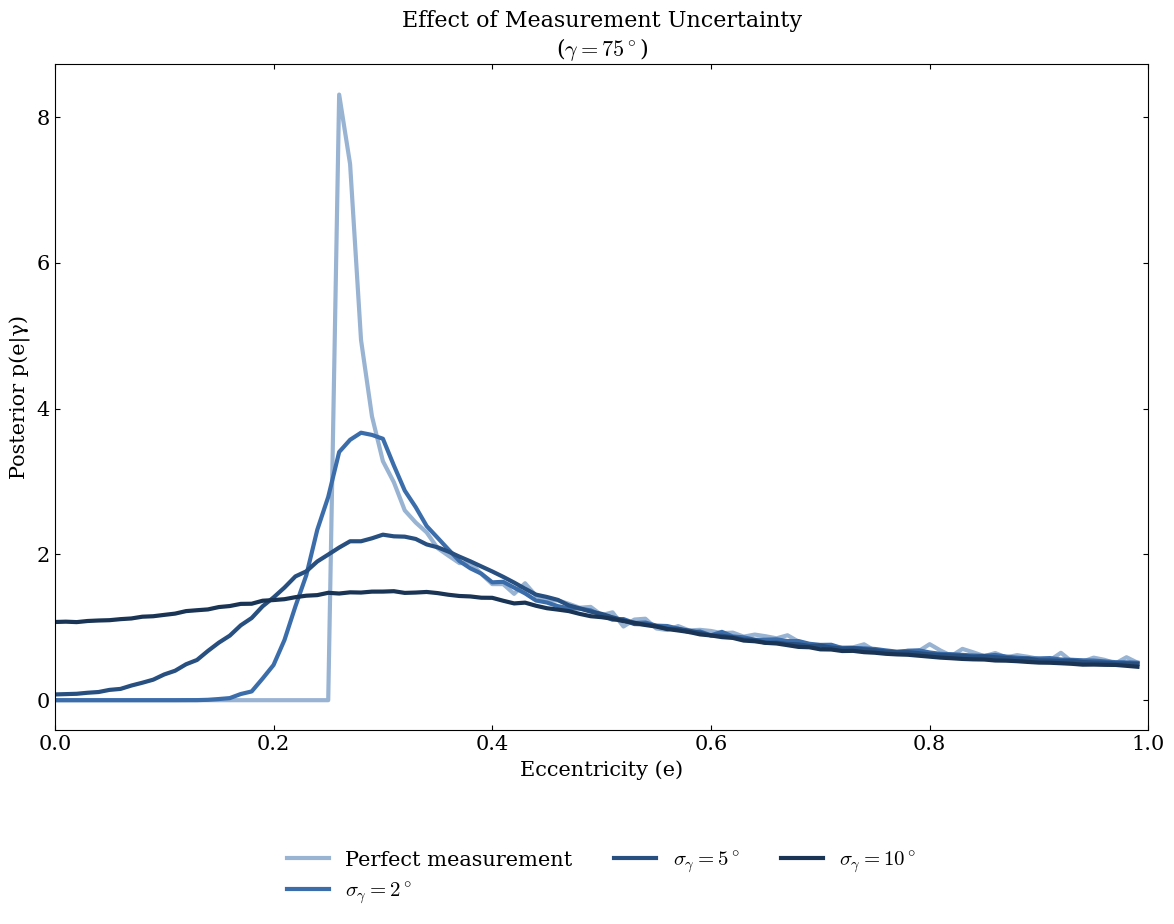

In [12]:
# Demonstrate the effect of measurement uncertainty
fig, ax = plt.subplots(figsize=(12.0, 9.6))

gamma_measured = 75
uncertainties = [0, 2, 5, 10]  # degrees
colors = plt.colormaps['book_blue'](np.linspace(0.25, 0.95, len(uncertainties)))

for sigma, color in zip(uncertainties, colors):
    if sigma == 0:
        # Perfect measurement
        e_grid, posterior = calculate_posterior(gamma_measured)
        label = 'Perfect measurement'
    else:
        # Gaussian measurement error
        e_grid, posterior = calculate_posterior_with_measurement_uncertainty(
            gamma_measured, sigma)
        label = r'$\sigma_\gamma = ' + f'{sigma}^\\circ$'

    ax.plot(e_grid, posterior, color=color, linewidth=3, label=label)

# Labels, title and limits
ax.set_xlabel('Eccentricity (e)')
ax.set_ylabel('Posterior p(e|γ)')
ax.set_title(r'Effect of Measurement Uncertainty' + f'\n($\\gamma = {gamma_measured}^\\circ$)')

# Legend and limits
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

A growing uncertainty widens the posterior and makes it harder to find the eccentricity precisely.

Next we compare how the same measurement uncertainty affects different observed angles.

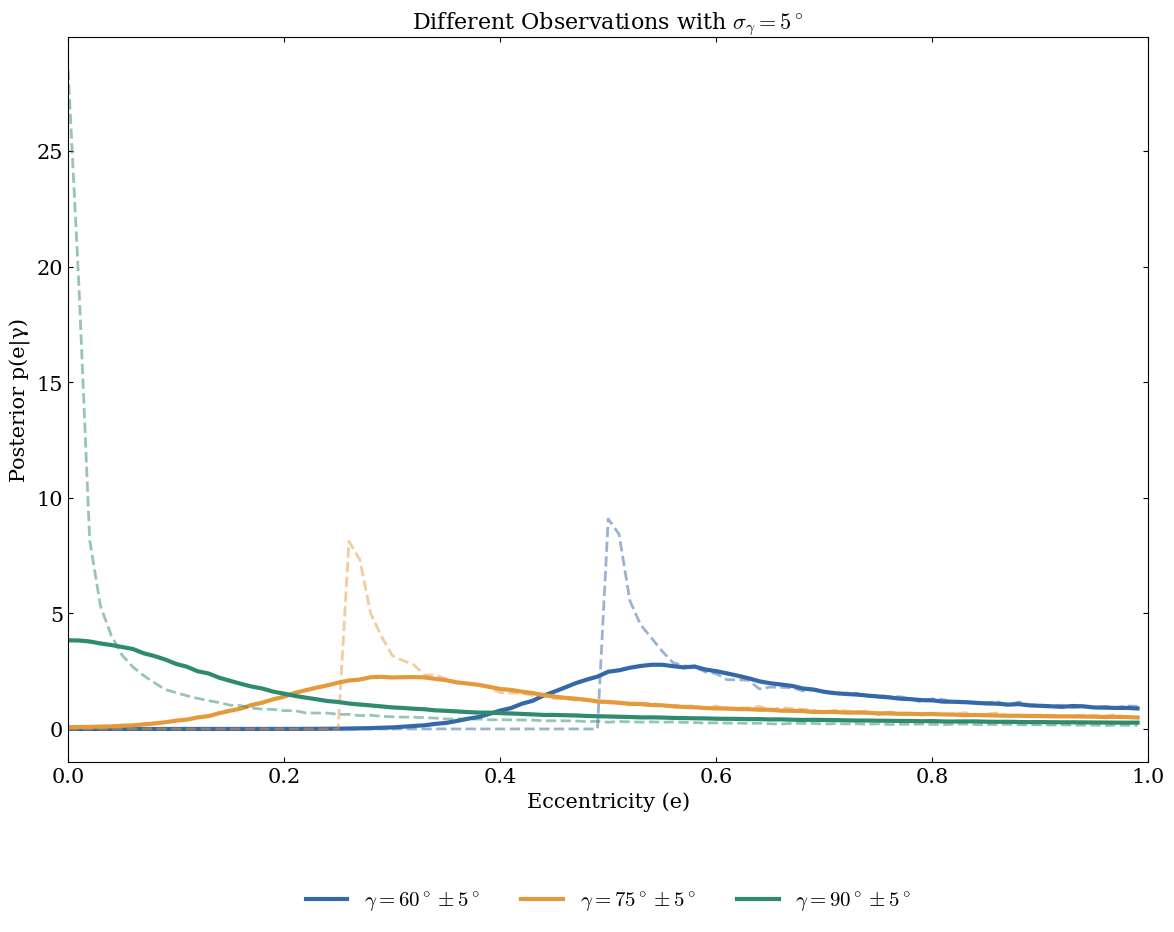

In [13]:
# Compare different γ values with fixed uncertainty
fig, ax = plt.subplots(figsize=(12.0, 9.6))

gamma_values = [60, 75, 90]
sigma_fixed = 5  # degrees
colors = ['C0', 'C1', 'C2']

for gamma, color in zip(gamma_values, colors):
    # Without uncertainty
    e_grid, post_perfect = calculate_posterior(gamma)
    ax.plot(e_grid, post_perfect, '--', color=color, alpha=0.5, linewidth=2)

    # With uncertainty
    e_grid, post_uncertain = calculate_posterior_with_measurement_uncertainty(
        gamma, sigma_fixed)
    ax.plot(e_grid, post_uncertain, '-', color=color, linewidth=3,
            label=r'$\gamma = ' + f'{gamma}^\\circ \\pm {sigma_fixed}^\\circ$')

# Labels, title and limits
ax.set_xlabel('Eccentricity (e)')
ax.set_ylabel('Posterior p(e|γ)')
ax.set_title(r'Different Observations with $\sigma_\gamma = ' + f'{sigma_fixed}^\\circ$')

# Legend and limits
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

To see how the measurement uncertainty enters, we draw the marginalization explicitly. The final posterior is a weighted average over the likelihoods of different true angles $\gamma_{\mathrm{true}}$. We show five of these likelihoods.

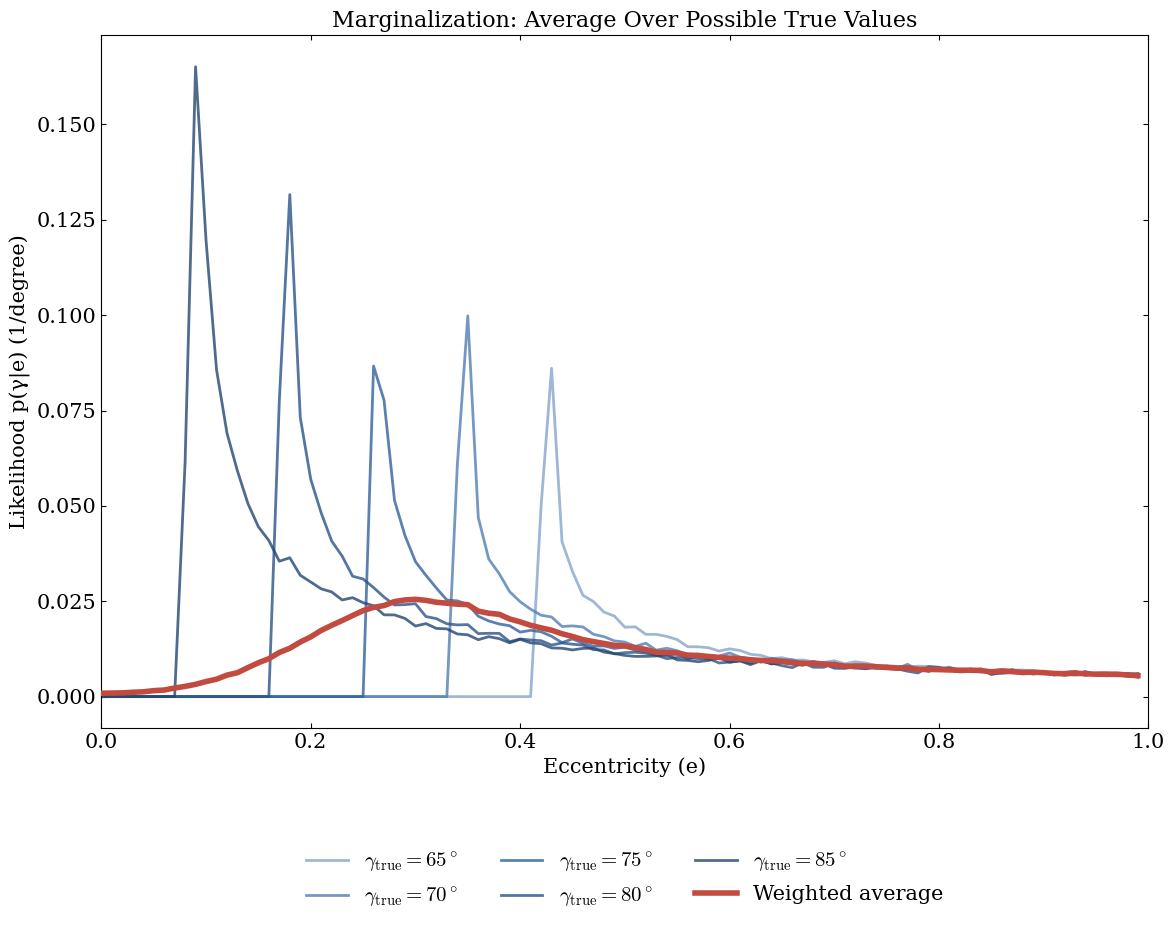

In [14]:
# Visualization of the marginalization process
fig, ax = plt.subplots(figsize=(12.0, 9.6))

gamma_measured = 75
sigma = 5

# Likelihoods and weights of all true angles, and the final posterior
e_grid, posterior_final, gamma_true, weights, likelihoods = \
    calculate_posterior_with_measurement_uncertainty(gamma_measured, sigma, return_curves=True)

# Pick five true angles, from -2 to +2 standard deviations
shown = [gamma_measured + k * sigma for k in (-2, -1, 0, 1, 2)]
colors_sample = plt.colormaps['book_blue'](np.linspace(0.3, 0.8, len(shown)))

# Plot the likelihood of each possible true gamma
for g, color in zip(shown, colors_sample):
    idx = np.argmin(np.abs(gamma_true - g))  # index of the grid angle closest to g
    ax.plot(e_grid, likelihoods[idx], color=color, alpha=0.8, linewidth=2,
            label=r'$\gamma_{\mathrm{true}} = ' + f'{g:.0f}^\\circ$')

# Plot the weighted average over all true angles
ax.plot(e_grid, weights @ likelihoods, '-', color='C3', linewidth=4,
        label='Weighted average', zorder=10)

ax.set_xlabel('Eccentricity (e)')
ax.set_ylabel('Likelihood p(γ|e) (1/degree)')
ax.set_title('Marginalization: Average Over Possible True Values')

# Legend and limits
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

A measurement error also widens the posterior and rounds the sharp lower edge, because we average over the possible true angles. Low eccentricities stay unlikely.


## Other Factors in a Real Analysis

We assumed a face-on orbit. Real orbits have an unknown inclination $i$, the angle between the normal of the orbital plane and our line of sight. A tilt projects the position and velocity vectors on the sky and changes the observed angle. We can include it with the recipe of this tutorial. We marginalize over a random direction of the line of sight in the frame of the orbit. This is the same step as for the phase and the measurement error.

An unknown inclination widens the posterior further and removes its sharp lower limit on the eccentricity. Projection lets a low-eccentricity orbit show an angle that only a more eccentric face-on orbit shows.

These results show why large surveys with precise measurements matter for population studies. A single observation with a realistic uncertainty gives only a wide range for an individual system. Many such observations together can reveal the eccentricity distribution of the population, which motivated the work of Hwang et al. (2022).


## Summary

In this tutorial we used Bayesian inference to infer a physical parameter from limited data. We constrained the eccentricity of a binary orbit from the angle between the position and the velocity at a single epoch. The same ideas apply to many problems of astronomical data analysis.

1. **Likelihood construction.** We built a forward model that links the eccentricity to the observable angle, and we inverted it with Bayes' theorem.
2. **Grid-based inference.** For this low-dimensional problem, we evaluated the posterior directly on a grid. This gave the complete posterior distribution.
3. **Marginalization.** We included two sources of uncertainty by integrating over unknown quantities. These are the orbital phase and the measurement error.
4. **Information content.** A single observation gives a broad posterior because of degeneracies. This is why population studies need large surveys.

The same recipe applies to other problems, for example measuring a dark matter halo from stellar kinematics or inferring exoplanet properties from transit photometry. We build a likelihood from the physics, apply Bayes' theorem, and marginalize over the uncertainties that we do not need. This gives constraints on the parameters of interest.